## **CMIP Climate Stripes with Julia**

#### **Purpose of this Tutorial**
* In this Script we will analyse the Climate Data using the Julia programming language. 
* Julia is an open source high level programming language (like Python, Matlab, R,...) that was published in 2012 and is mainly used for scientific programming. 
* The main difference of Julia compared to Python, R or Matlab is its speed. We will explore this characteristic in the following tutorial generating the climate stripes and comparing the performance to a Python implementation

#### **Setup**
1. Download Julia from https://github.com/JuliaLang/juliaup#installation
2. Install Julia extension in Visual Code Studio market place
3. Code can be execute in 
    - Julia Read-Eval-Print-Loop (Julia: Start REPL)
    - Jupyter Notebook
    - ...
4. When selecting the Kernel in Jupyter:
    - Julia release channel (automatically uses most recent version of Julia on your machine)

In [9]:
print("Hello World")

Hello World

#### **CMIP Data Analysis: Packages used**
* **Rasters**: Julia package for labeled multidimensional array and geospatial raster manipulation (Python equivalent: `xarray` / `rioxarray`).
* **NCDatasets**: Backend library for reading, writing, and inspecting NetCDF files (Python equivalent: `netCDF4`).
* **Dates**: Built-in standard library for handling calendar dates, timestamps, and time intervals (Python equivalent: `datetime`).
* **Statistics**: Built-in standard library providing basic statistical reductions like `mean` and `std` (Python equivalent: `numpy` statistical functions).
* **CairoMakie**: High-performance, publication-quality 2D vector and static plotting backend for the Makie ecosystem (Python equivalent: `matplotlib`).
* **GeoMakie**: Cartographic extension for Makie that adds map projections and coastlines (Python equivalent: `cartopy`).
* **BenchmarkTools**: Precision performance tracking library that handles JIT compilation warm-up and statistical timing (Python equivalent: ´timeit`).
* **PythonCall**: Package that allows to call Python from Julia (loads numpy library as specified in `CondaPkg.toml`)

In [1]:
using Pkg
Pkg.activate(".")
Pkg.add(["Rasters", "NCDatasets", "Dates", "Statistics"])
Pkg.add(["CairoMakie", "GeoMakie", "PythonCall", "BenchmarkTools"])
# Pkg.instantiate()

using Rasters, NCDatasets, Dates, Statistics
using CairoMakie, GeoMakie
using PythonCall, BenchmarkTools

  Activating project at `c:\Users\timauc002\Documents\GitHub\Julia CMIP`
     Project No packages added to or removed from `C:\Users\timauc002\Documents\GitHub\Julia CMIP\Project.toml`
    Manifest No packages added to or removed from `C:\Users\timauc002\Documents\GitHub\Julia CMIP\Manifest.toml`
     Project No packages added to or removed from `C:\Users\timauc002\Documents\GitHub\Julia CMIP\Project.toml`
    Manifest No packages added to or removed from `C:\Users\timauc002\Documents\GitHub\Julia CMIP\Manifest.toml`
    CondaPkg Found dependencies: C:\Users\timauc002\Documents\GitHub\Julia CMIP\CondaPkg.toml
    CondaPkg Found dependencies: C:\Users\timauc002\.julia\packages\CondaPkg\Pc7ZA\CondaPkg.toml
    CondaPkg Found dependencies: C:\Users\timauc002\.julia\packages\PythonCall\trYos\CondaPkg.toml
    CondaPkg Initialising pixi
             │ C:\Users\timauc002\.julia\artifacts\6cd2217b3e33a22947fb8d4194f79fd44c7dc25f\bin\pixi.exe
             │ init
             │ --format pixi
  

#### **Python vs Julia**

**Design**
- Both Python and Julia are high level languages (human readible)
- Both languages use dynamic typing, so variables types do not need to be defined beforehand
- However, they differ in the way how code is translated to machine code
    - **Python** is an interpreter languge and compiles code into intermediate bytecode (saved in `__pycache__`), which the interpreter then executes step-by-step at runtime without compiling it into native CPU machine code.
    - **Julia** uses JIT (just in time) compilation, where a function is compiled just before it is called based on the type of the arguments that are passed to the function (multiple dispatch)
    - In **C** the whole program code is compiled before execution

**Syntax**
- Julia has 1-based indexing (vs. Python 0 based), e.g. `x=[0,1,2], x[1]=0`
- Julia needs `end` keyword for block termination but does not care about indentation 
- Julia differentiates between characters (single quotes: `'h'`) and strings (double quotes: `"hello world"`)
- Macros are statements that start with an `@` through which we can give commands to the compiler

**Speed**
- Python has functions that are precompiled in **C**
    - If you use only these functions, python will not be slower than Julia
    - If you use a lot of custom functions with loops and conditionals, they will be faster in Julia
- Generally
    - Use python for deep learning, tabular data processing (pandas) or general software engineering (object oriented)
    - Use julia for scientific coding (differential equations, ABMs, physical models, ...) and mathematics and optimisation

In the following we are going to showcase these performance differences between Python and Julia based on the CMIP data. 

In [2]:
# Use PythonCall to import Pythons xarray and numpy
xr = pyimport("xarray")
np = pyimport("numpy");

In [3]:
path = "." # put path to file on your machine here
file = "tas_Amon_ACCESS-CM2_historical_r1i1p1f1_gn_185001-201412.nc"
filepath = joinpath(path, file)

# Load in Julia and convert to concrete Float32 (since tas has no missing values)
# Rasters.checkmem!(false) # Turn off the macOS free-RAM check globally for the session
tas_raw_jl = Raster(filepath, name=:tas) # load file and select tas variable

┌ 192×144×1980 Raster{Union{Missing, Float32}, 3} tas ┐
├─────────────────────────────────────────────────────┴────────────────── dims ┐
  ↓ X Mapped{Float64} 0.9375:1.875:359.0625 ForwardOrdered Regular Intervals{Center},
  → Y Mapped{Float64} -89.375:1.25:89.375 ForwardOrdered Regular Intervals{Center},
  ↗ Ti Sampled{DateTime} [DateTime("1850-01-16T12:00:00"), …, DateTime("2014-12-16T12:00:00")] ForwardOrdered Explicit Intervals{Center}
├──────────────────────────────────────────────────────────────────── metadata ┤
  Metadata{Rasters.NCDsource} of Dict{String, Any} with 10 entries:
  "cell_methods"  => "area: time: mean"
  "coordinates"   => "height"
  "_FillValue"    => 1.0f20
  "missing_value" => 1.0f20
  "standard_name" => "air_temperature"
  "long_name"     => "Near-Surface Air Temperature"
  "units"         => "K"
  "history"       => "2019-11-08T06:41:45Z altered by CMOR: Treated scalar dime…
  "comment"       => "near-surface (usually, 2 meter) air temperature"
  "cell_measu

**Raster File Summary**
- First Section (`192×144×1980 Raster{Union{Missing, Float32}, 3} tas`): three dimensions, each value can either be float or Missing
    - The file acutally does not contain missing values
    - Doing the calculation with one variable type increases speed dramatically
- Second Section: Axis dimensions, longitude, latitude and time stamp
- Third Section: Metadata
- Fourth Section: Spatial and temporal extend and coordinate system

In [4]:
# modiy is a function of Rasters.jl that modifes the values type while keeping the dimensions and metadata
tas_clean_jl = modify(Array{Float32}, tas_raw_jl);

In [5]:
# Load in Python via xarray (.load() forces it into RAM for a fair benchmark
ds_py = xr.open_dataset(filepath).load()
tas_raw_py = ds_py["tas"]; # select the tas variable from the xarray dataset

#### **Calculate temperature Anomaly**
We now calculate the temperature anomaly doing the following steps
1. Convert temperature from Kelvin to degree celsius
2. Define a reference period (1980-2010) and a analysis period (1979-2015)
3. Compute the average monthly temperature for the reference period
4.  Substract from analysis period


In [10]:
function calc_anom_native_jl(tas_raw)
    # Convert to °C
    tas = tas_raw .- 273.15f0
    
    # Slice reference (360 months) and analysis (432 months) periods
    # @view is a macro that specifies that the slice is not copied into new memory
    # we can do this here because we do not modify the reference period
    tas_ref = @view tas[Ti(DateTime(1981, 1, 1) .. DateTime(2011, 1, 1))]
    tas_period = tas[Ti(DateTime(1979, 1, 1) .. DateTime(2015, 1, 1))]
    
    nx, ny, nt_ref = size(tas_ref) # return dimensions of reference period (X,Y,Ti)
    nt_per = size(tas_period, 3) # number of time steps in analysis period (432 months)
    
    # Compute average temperature for every month in reference period (192 × 144 × 12)
    clim = zeros(Float32, nx, ny, 12) # create array of 0s to hold monthly averages
    n_years_ref = nt_ref ÷ 12 # number of years in the reference period (÷ is integer division, like python //, type \dif and tab)
    
    # @inbound is a macro that tells Julia to skip some securtity checks when processing an array (speed up)
    @inbounds for m in 1:12
        for k in 0:(n_years_ref - 1)
            t = m + k * 12 # compute time intex for current month m and year k (january first year = 1, january second year = 13, etc.)
            # @simd  tells the processor to process multiple values in parallel (speed up)
            @simd for i in 1:(nx * ny)
                # The array is saved as a linear array in memory, so we also index it in this way
                # For each grid cell and month m in clim, we add the corresponding grid value of each month in tas_ref, indexed by t
                # (m - 1) * nx * ny calculates the offset in the linear array
                clim[i + (m - 1) * nx * ny] += tas_ref.data[i + (t - 1) * nx * ny]
            end
        end
    end
    clim ./= n_years_ref
    
    # Subtract monthly climatology in-place
    tas_anom = copy(tas_period)
    @inbounds for t in 1:nt_per
        m = mod1(t, 12)
        for y in 1:ny
            @simd for x in 1:nx
                tas_anom.data[x, y, t] -= clim[x, y, m]
            end
        end
    end
    
    return tas_anom
end;

In [6]:
function calc_anom_native_jl(tas_raw)
    # Convert to °C
    tas = tas_raw .- 273.15f0
    
    # Slice reference (360 months) and analysis (432 months) periods
    # @view is a macro that specifies that the slice is not copied into new memory
    # we can do this here because we do not modify the reference period
    tas_ref = @view tas[Ti(DateTime(1981, 1, 1) .. DateTime(2011, 1, 1))]
    tas_anom = tas[Ti(DateTime(1979, 1, 1) .. DateTime(2015, 1, 1))]
    
    nx, ny, nt_ref = size(tas_ref) # return dimensions of reference period (X,Y,Ti)
    nt_per = size(tas_anom, 3) # number of time steps in analysis period (432 months)
    
    # Compute average temperature for every month in reference period (192 × 144 × 12)
    clim = zeros(Float32, nx, ny, 12) # create array of 0s to hold monthly averages
    n_years_ref = nt_ref ÷ 12 # number of years in the reference period (÷ is integer division, like python //, type \dif and tab)
    
    # @inbound is a macro that tells Julia to skip some securtity checks when processing an array (speed up)
    @inbounds for m in 1:12
        for k in 0:(n_years_ref - 1)
            t = m + k * 12 # compute time intex for current month m and year k (january first year = 1, january second year = 13, etc.)
            for y in 1:ny
                # @simd  tells the processor to process multiple values in parallel (speed up)
                @simd for x in 1:nx
                    # sum the grid values for each month of every year in the ref period
                    clim[x, y, m] += tas_ref.data[x, y, t]
                end
            end
        end
    end

    # calculate the monthly average. 
    clim ./= n_years_ref # the . operator ensures that division is applied element wise
    
    # Subtract monthly averages from analysis period
    @inbounds for t in 1:nt_per
        m = mod1(t, 12) # modulo function that returns month index, for perfect multiple returns 12 instead of 0 (mod1(12, 12) = 12))
        for y in 1:ny
            @simd for x in 1:nx
                tas_anom.data[x, y, t] -= clim[x, y, m]
            end
        end
    end
    
    return tas_anom
end;

In [7]:
# here we implement the same algorithm using first native Python loops and then xarray to show the key differences
# in performance between Julia and Python!

@pyexec """
def calc_anom_native_py(tas_da):
    import numpy as np  # <-- Put the import INSIDE the function!
    
    # Slice periods using xarray, then extract raw 3D numpy arrays (time, lat, lon)
    ref_arr = (tas_da.sel(time=slice('1981-01-01', '2010-12-31')).values - 273.15)
    per_arr = (tas_da.sel(time=slice('1979-01-01', '2014-12-31')).values - 273.15)
    
    nt_ref, ny, nx = ref_arr.shape
    nt_per = per_arr.shape[0]
    
    # Compute 12 monthly climatologies using native Python loops
    clim = np.zeros((12, ny, nx), dtype=np.float32)
    for m in range(12):
        for y in range(ny):
            for x in range(nx):
                total = 0.0
                count = 0
                for t in range(m, nt_ref, 12):
                    total += ref_arr[t, y, x]
                    count += 1
                clim[m, y, x] = total / count
                
    # Subtract monthly climatology from 1979-2014 period
    anom = np.empty_like(per_arr)
    for t in range(nt_per):
        m = t % 12
        for y in range(ny):
            for x in range(nx):
                anom[t, y, x] = per_arr[t, y, x] - clim[m, y, x]
                
    return anom
""" => calc_anom_native_py

@pyexec """
def calc_anom_xarray_py(tas_da):
    tas = tas_da - 273.15
    tas_ref = tas.sel(time=slice('1981-01-01', '2010-12-31'))
    tas_clim = tas_ref.groupby('time.month').mean('time')
    
    # Optimization: slice 1979-2014 BEFORE groupby subtraction so we don't 
    # waste time computing anomalies for 1850-1978
    tas_period = tas.sel(time=slice('1979-01-01', '2014-12-31'))
    tas_anom = tas_period.groupby('time.month') - tas_clim
    return tas_anom.values
""" => calc_anom_xarray_py

Python: <function calc_anom_xarray_py at 0x000002794DEE4220>

In [8]:
# Benchmarking
println("1. Native Python (Interpreted for-loops):")
# We use @time (1 run) instead of @btime here because Python loops take ~5-8 seconds per run!
@time res_py_loop = calc_anom_native_py(tas_raw_py);

println("\n2. Python Fast Operation (Vectorized xarray groupby):")
@btime calc_anom_xarray_py($tas_raw_py);

println("\n3. Native Julia (JIT-compiled for-loops):")
@btime calc_anom_native_jl($tas_clean_jl);

# Validate outputs are approximately equal
res_xr_np = pyconvert(Array{Float32, 3}, calc_anom_xarray_py(tas_raw_py))
res_py_np = pyconvert(Array{Float32, 3}, res_py_loop)
res_jl = calc_anom_native_jl(tas_clean_jl)
res_jl_array = Array(res_jl) # convert Rasters.jl Raster to a standard Julia array for comparison

# Note: Python arrays are (time, lat, lon) = (432, 144, 192), 
# while Julia Rasters are (lon, lat, time) = (192, 144, 432).
# We permute Python's dimensions to (3, 2, 1) to compare grid cell by grid cell:
res_xr_permuted = permutedims(res_xr_np, (3, 2, 1))
res_py_permuted = permutedims(res_py_np, (3, 2, 1))

println("\nAre all three results approximately equal (≈)? ", res_jl_array ≈ res_xr_permuted ≈ res_py_permuted)
println("Max absolute difference (Xarray vs Julia): ", maximum(abs.(res_jl_array .- res_xr_permuted)))

1. Native Python (Interpreted for-loops):
  9.664620 seconds (6.35 k allocations: 320.045 KiB, 0.59% compilation time)

2. Python Fast Operation (Vectorized xarray groupby):
  297.962 ms (9 allocations: 208 bytes)

3. Native Julia (JIT-compiled for-loops):
  149.671 ms (18 allocations: 255.67 MiB)

Are all three results approximately equal (≈)? true
Max absolute difference (Xarray vs Julia): 0.0


#### Visualization

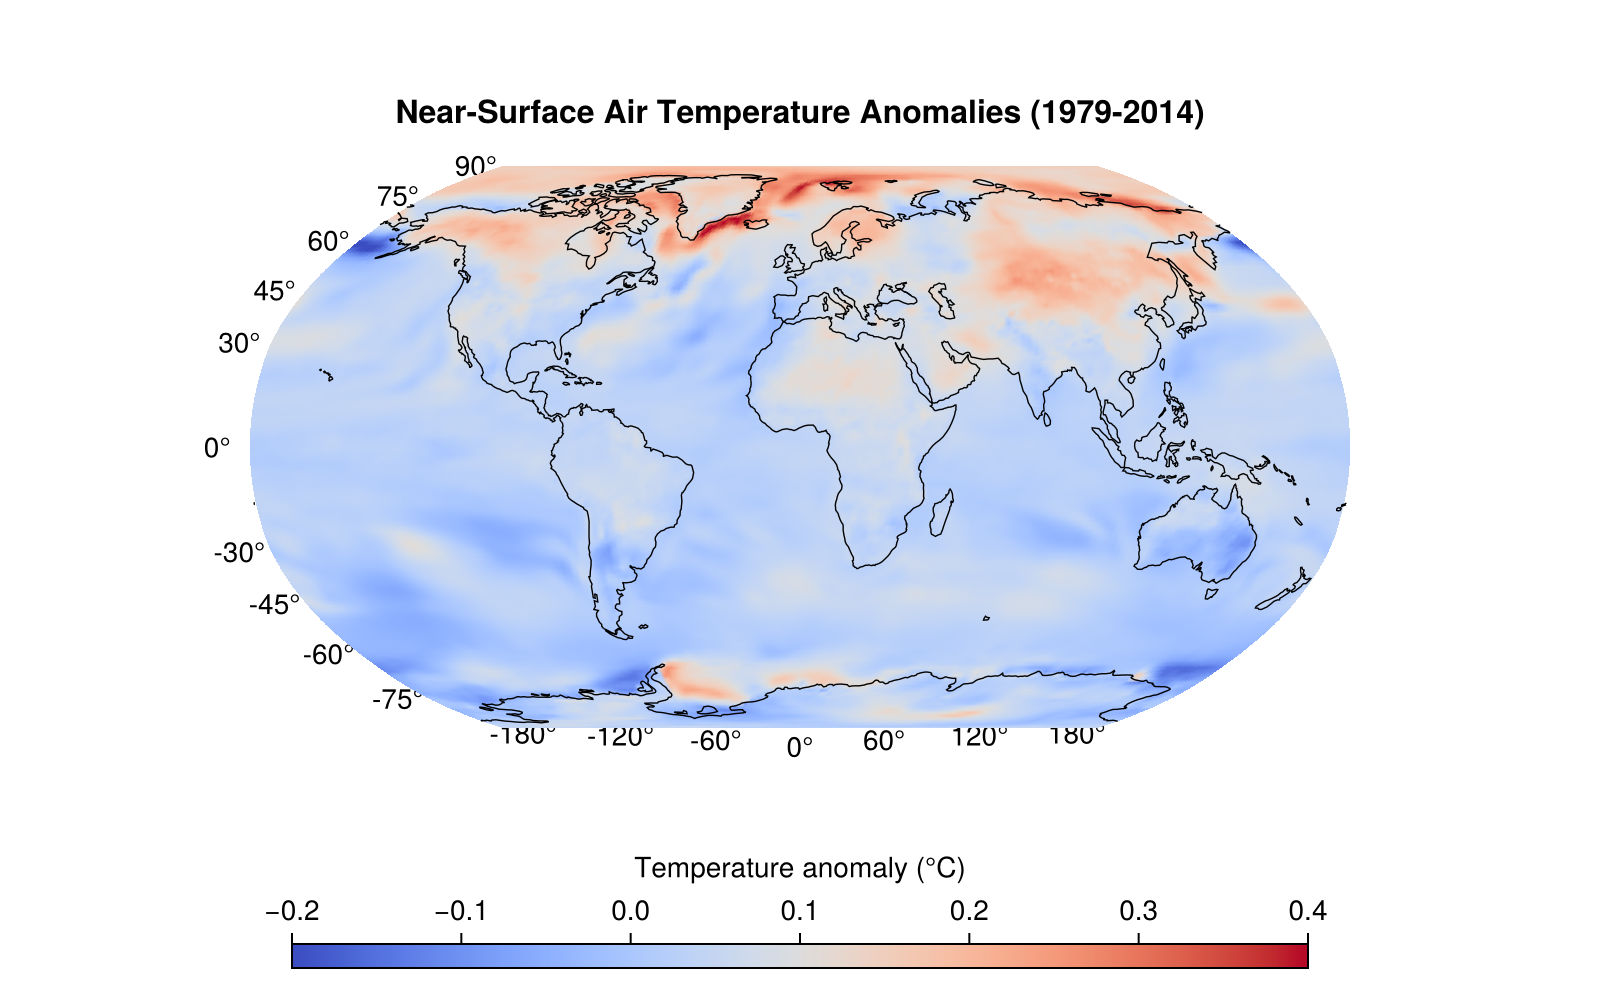

In [9]:
# Calculate mean temperature anomaly per cell over the whole period of analysis (1979-2014)
tas_anom_mean = dropdims(mean(res_jl, dims=Ti), dims=Ti)

# Extract coordinates and data
lons = collect(lookup(tas_anom_mean, X))
lats = collect(lookup(tas_anom_mean, Y))
data_matrix = Matrix(tas_anom_mean)

# Shift longitudes from [0, 360] to [-180, 180] because that is standard for projection in GeoMakie
split_idx = findfirst(x -> x > 180, lons) # Find the first index where the longitude crosses 180°
# Bring the >180 half to the front and subtract 360 to make them negative
lons_shifted = vcat(lons[split_idx:end] .- 360, lons[1:split_idx-1]) # vcat is vertical concatenate (stack the lons in the new order)
# Do the same shift to the data matrix along the X axis (rows) to match the new longitude order
data_shifted = vcat(data_matrix[split_idx:end, :], data_matrix[1:split_idx-1, :])

# Create Figure with standard Greenwich-centered projection
fig = Figure(size = (800, 500))
ga = GeoAxis( # project the data onto a Robinson projection
    fig[1, 1];
    dest = "+proj=robin", # Edges are now strictly ±180°
    title = "Near-Surface Air Temperature Anomalies (1979-2014)",
    titlesize = 16,
    xgridvisible = false,
    ygridvisible = false
)
# Plot the surface using the shifted longitudes and data
sp = surface!(
    ga, # projection from Geoaxis
    lons_shifted, 
    lats, 
    data_shifted;
    colormap = :coolwarm,
    colorrange = (-0.2, 0.4),
    shading = NoShading
)

# add coastlines
lines!(ga, GeoMakie.coastlines(), color = :black, linewidth = 0.7)

# Add horizontal colorbar
Colorbar(
    fig[2, 1], sp; 
    vertical = false, 
    label = "Temperature anomaly (°C)", 
    width = Relative(0.7)
)

fig

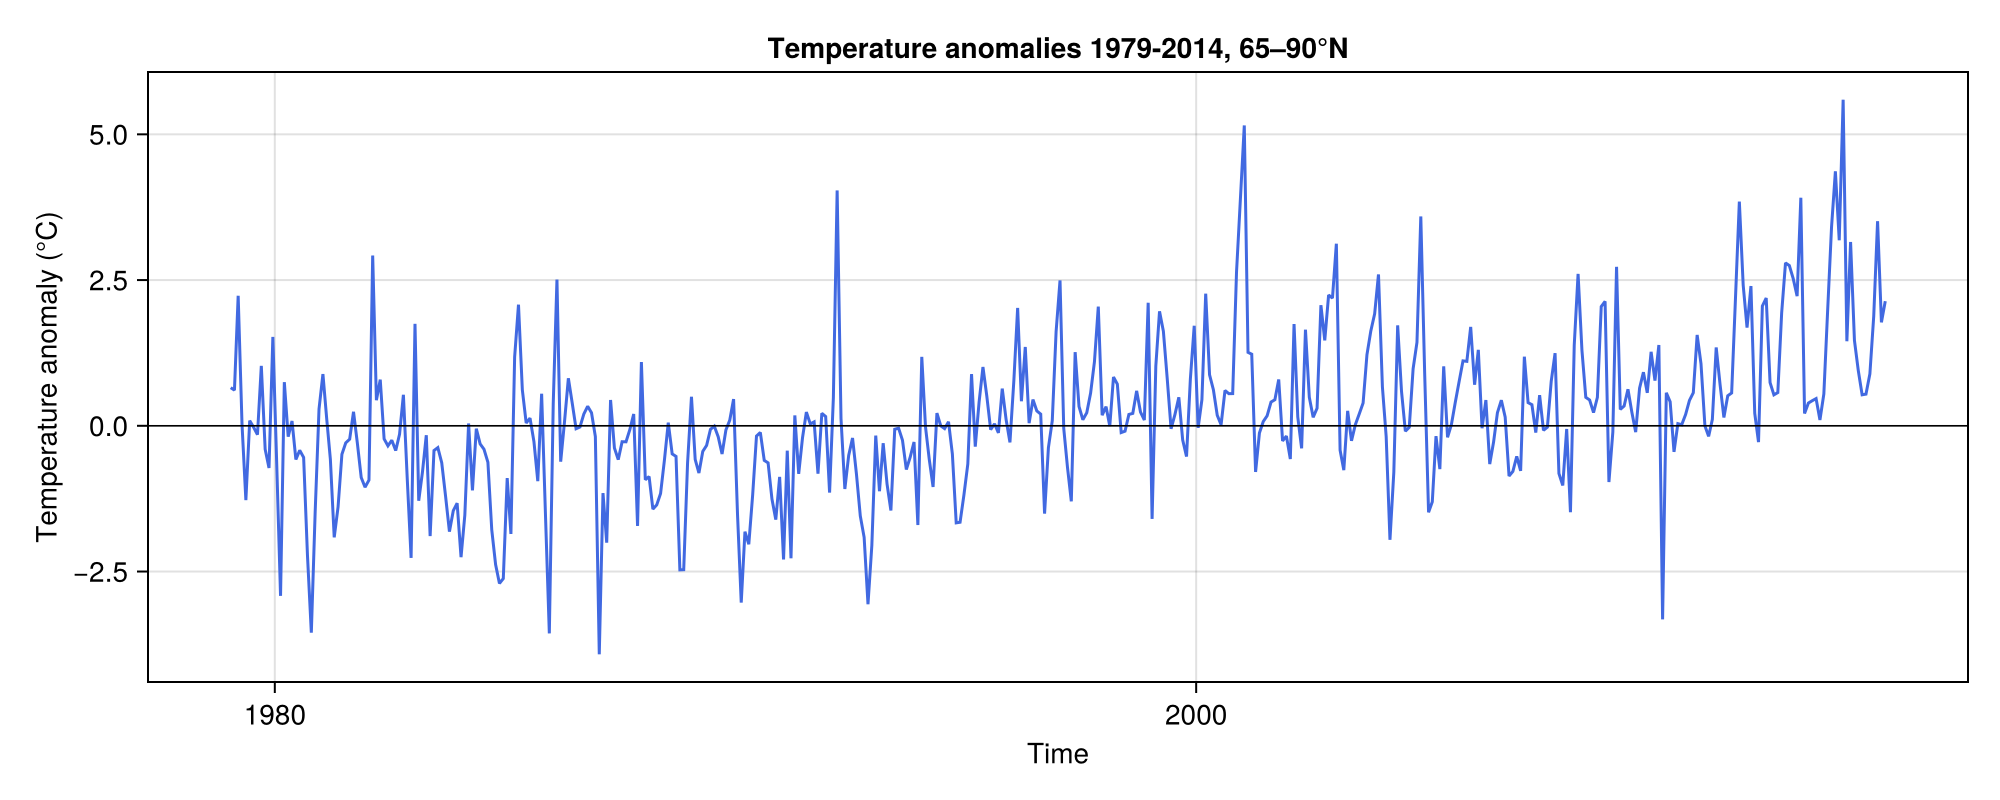

CairoMakie.Screen{IMAGE}


In [10]:
# Plot temperature curve of arctiv region
# Select 65-90°N and average over lon (X) and lat (Y)
tas_65_90N = dropdims(mean(res_jl[Y(65 .. 90)], dims=(X, Y)), dims=(X, Y))
time_axis = lookup(tas_65_90N, Ti) # Extract time steps

time_data = collect(time_axis) # Extract a standard Vector{DateTime} from the Raster data
temp_data = collect(tas_65_90N) # Convert to standard Vector{Float32} from the Raster data

tick_positions = collect(DateTime(1980, 1, 1):Year(5):DateTime(2015, 1, 1))

fig_line = Figure(size = (1000, 400))
ax = Axis(
    fig_line[1, 1],
    xlabel = "Time",
    ylabel = "Temperature anomaly (°C)",
    title = "Temperature anomalies 1979-2014, 65–90°N",
    )

# Plot DateTimes directly on the X-axis
lines!(ax, time_data, temp_data, color = :royalblue, linewidth = 1.5)
hlines!(ax, [0.0], color = :black, linewidth = 0.8)

display(fig_line)

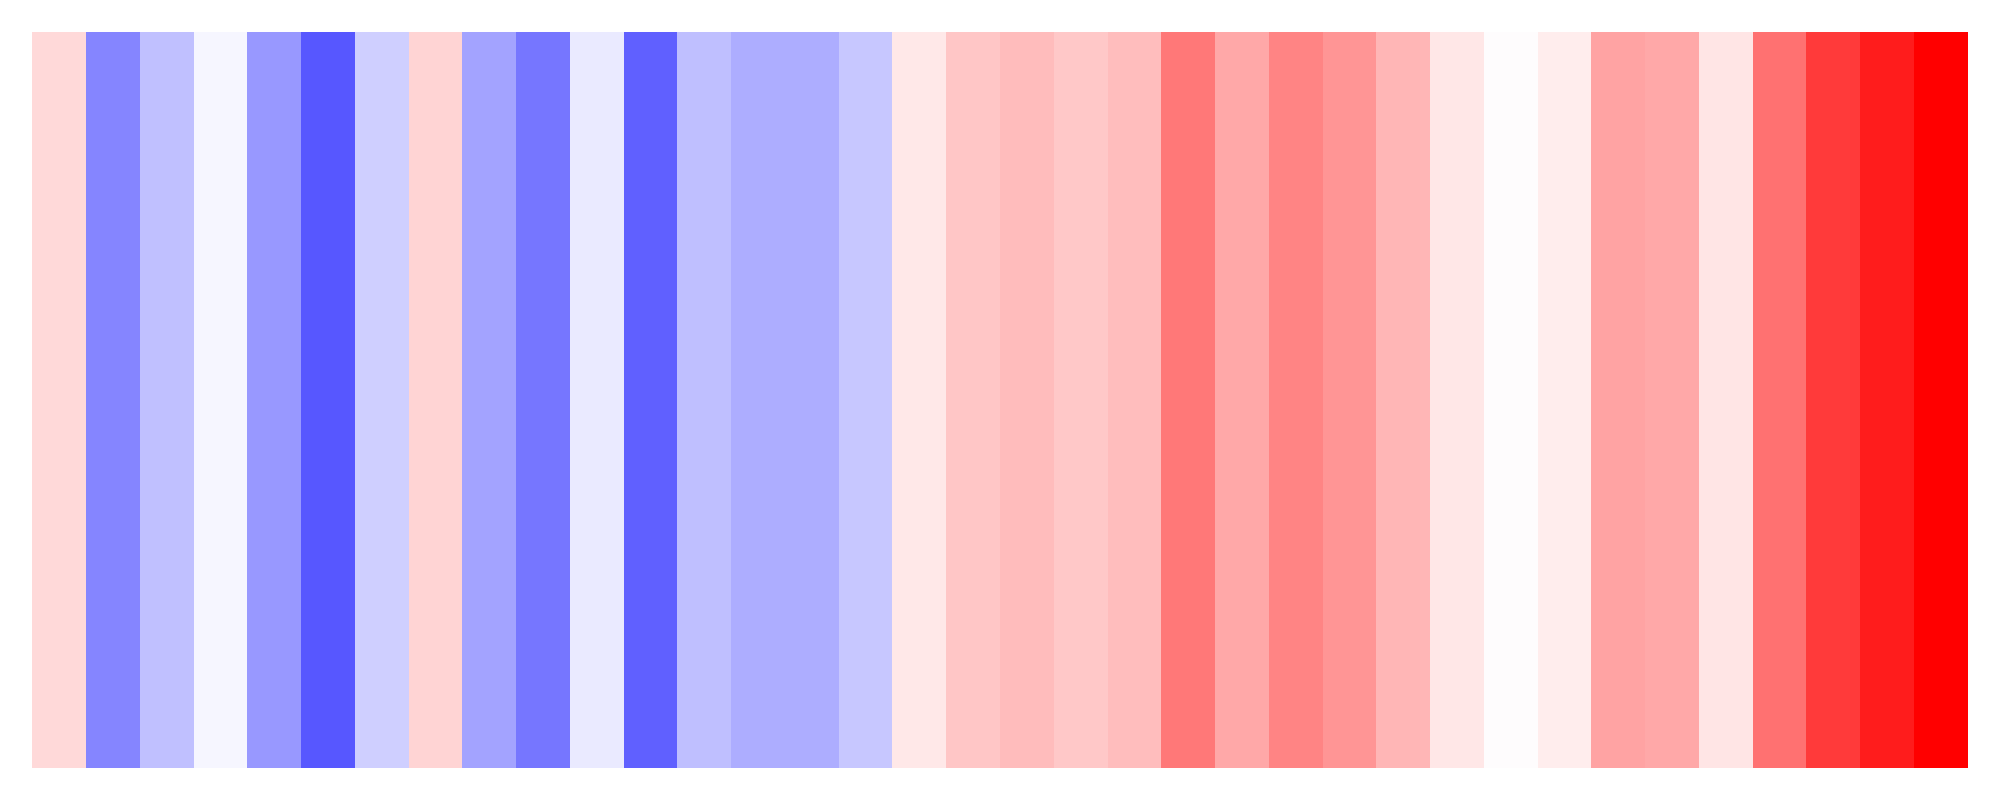

CairoMakie.Screen{IMAGE}


In [11]:
# Climate Stripes
temperature = mean.(groupby(tas_65_90N, Ti => year)) # group by year and calculate the mean for each year
years = unique(year.(time_axis)) # get unique years from the time axis

limit = maximum(abs.(temperature)) # get largest temp anomaly

fig_stripes = Figure(size = (1000, 400))
ax_stripes = Axis(fig_stripes[1, 1])
hidedecorations!(ax_stripes) # hide all ticks, lines and labels of a standard plot
hidespines!(ax_stripes) # hide bounding box

heatmap!(
    ax_stripes, 
    years, 
    [1], # y-axis dummy value
    reshape(temperature, :, 1); # Reshape 1D vector to an (N_years, 1) matrix for the heatmap
    colormap = :bwr,
    colorrange = (-limit, limit)
)

display(fig_stripes)